# Exercise 1
Nico Reiterer - 5191 2112

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1.1. - Approximation of the integral

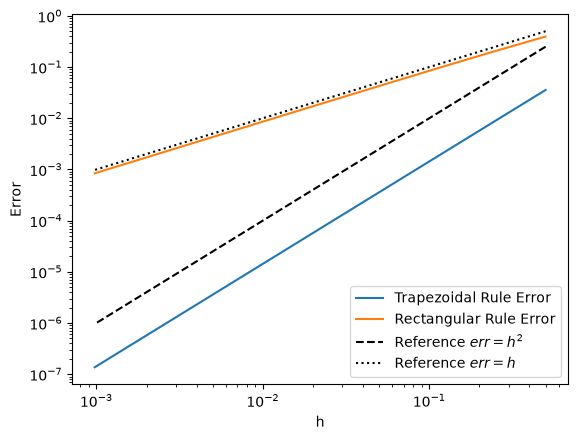

In [ ]:
def T(h: float, f: callable) -> float:
    """
    Implementation of the trapezoidal rule for numerical integration.
    """
    N = round(1 / h)

    # x_i = i * h
    x = np.arange(0, N+1) * h # N + 1 because the last point is i + 1, so not N-1, but N ..

    y = f(x)
    h = 1 / N

    
    return h * (0.5 * y[0] + y[1:-1].sum() + 0.5 * y[-1])

def R(h: float, f:callable) -> float:
    """
    IMplementation of the box rule for numerical integration.
    """
    N = round(1 / h)

    # x_i = i * h
    x = np.arange(0, N) * h

    y = f(x)
    h = 1 / N
    
    return h * y.sum()

def f(x: np.ndarray) -> np.ndarray:
    """
    Function to be integrated in 1b.
    """
    return np.exp(x)

def N(i: int) -> float:
    return 2 ** (i + 1)

def calc_1b_error(h: np.ndarray, f: callable, appr: callable) -> np.ndarray:
    """
    Calculate the error for the trapezoidal rule.
    """

    err = np.zeros_like(h)
    for i in range(len(h)):
        err[i] = np.exp(1) - 1 - appr(h[i], f)

    return err

h = 1 / N(np.arange(0, 10))
plt.loglog(h, np.abs(calc_1b_error(h, f, T)), label="Trapezoidal Rule Error")
plt.loglog(h, np.abs(calc_1b_error(h, f, R)), label="Rectangular Rule Error")
plt.loglog(h, h**2, "k--", label="Reference $err = h^2$")
plt.loglog(h, h, "k:", label="Reference $err = h$")
plt.xlabel("h")
plt.ylabel("err")
plt.legend()
plt.show()

**Does the true error behave like $Ch^2$?**

Yes, the true error behaves like $Ch^2$ for the trapezoidal rule. The error decreases quadratically as the step size $h$ decreases, which is I guess consistent with the theory!

**Do the same thing for the box rule as well. What error behaviour do you see?**

We see a linear decrease in the error as the step size $h$ decreases.

## 1.2. - Design of an error estimator

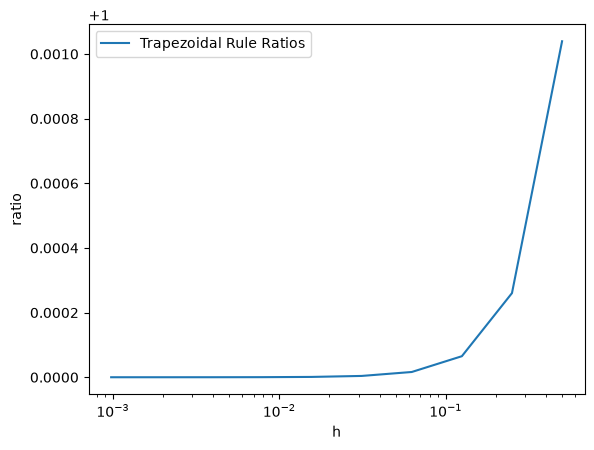

In [ ]:
# a) Making the Ansatz
def C(h: float, f: callable, T: callable) -> float:
    """
    Calculate the constant C for the trapezoidal rule.
    """
    y = 1 / h**2 * 4 / 3 * (T(h/2, f) - T(h, f))
    return y

def E(h: float, f: callable, T: callable) -> float:
    """
    Calculate the error for the trapezoidal rule, which is C * h^2, hence taking the same as above but w/out the 1/h^2 factor.
    """
    y = 4 / 3 * (T(h/2, f) - T(h, f))
    return y

# b) Computing the ratios r(i) := err(i) / E(h(i))
def calc_ratios(h: np.ndarray, f: callable, appr: callable) -> np.ndarray:
    """
    Calculate the ratios of the true error to estimated error: 
        r(i) := err(i) / E(h(i)) for the trapezoidal rule.
    """

    err = calc_1b_error(h, f, appr)
    E_vals = np.array([E(h_i, f, appr) for h_i in h])
    return err / E_vals

h = 1 / N(np.arange(0, 10))
plt.semilogx(h, calc_ratios(h, f, T), label="Trapezoidal Rule Ratios")
plt.xlabel("h")
plt.ylabel("ratio")
plt.legend()
plt.show()